# 08 · RDM correlation matrices, any datasets

**What it does.** For any 2+ of `bv vedb things imagenet lvis` on their shared categories: the RDM-to-RDM Spearman
matrix per model with category-bootstrap 95% CIs, and a dataset × backbone matrix (every dataset under both CLIP
and DINOv3), which shows how much each dataset's category geometry depends on the backbone.

**Outputs:** `outputs/rdm_matrices/<datasets>/results/` and `figures/`.

In [1]:
# Standard setup shared by every notebook (each notebook is self-contained).
import json
import os
import random
import re
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch, Rectangle
from scipy.cluster.hierarchy import leaves_list, linkage, optimal_leaf_ordering
from scipy.spatial.distance import pdist, squareform
from scipy.stats import false_discovery_control, pearsonr, rankdata, spearmanr, wilcoxon
from IPython.display import Image, Markdown, display

plt.rcParams["font.family"] = ["DejaVu Sans", "sans-serif"]
pd.set_option("display.max_colwidth", 120)


def show_images(paths, width=950):
    """Display saved figures (the files this notebook writes)."""
    for p in map(Path, paths):
        if p.exists():
            display(Markdown(f"`{p.relative_to(ROOT)}`")); display(Image(filename=str(p), width=width))
        else:
            display(Markdown(f"*Missing figure:* `{p}`"))

In [2]:
# Paths. Run this notebook from analysis/comparison-datasets/notebooks/ (Jupyter's default working directory).
ROOT = Path.cwd().resolve().parent                     # analysis/comparison-datasets
assert (ROOT / "notebooks").is_dir(), "open this notebook from analysis/comparison-datasets/notebooks/"
REPO = ROOT.parents[1]
DATA_DIR = REPO / "data"
MANUSCRIPT_DIR = REPO / "analysis" / "manuscript-2026"
VEDB_DIR = REPO / "analysis" / "vedb-1612"
VOCAB_DIR = DATA_DIR / "vocabulary_lists"
VALID129_TXT = VOCAB_DIR / "included_categories_valid129.txt"

# Inputs written by other pipelines (read only).
EXEMPLAR_EMBED_ROOT = Path(os.environ.get("BV_EXEMPLAR_EMBED_ROOT",
                                          str(MANUSCRIPT_DIR / "exemplar_set_embeddings"))).expanduser()
BV_THINGS_VALID129 = EXEMPLAR_EMBED_ROOT / "valid129"       # manuscript Stage 0: BV + THINGS tables
VEDB_VALID129 = VEDB_DIR / "exemplar_set_embeddings" / "valid129"   # vedb-1612 Stage 0 (files use the "bv_" prefix)

# External data on ccn2.
IMAGENET_DIR = Path("/data2/j7yang/imagenet-1k/extracted")
IMAGENET_EMBED_ROOT = Path("/ccn2a/dataset/babyview/related_data/imagenet_1k/outputs/image_embeddings")
LVIS_ROOT = Path("/data2/j7yang/lvis")
LVIS_CROP_EMBED_ROOT = Path("/ccn2a/dataset/babyview/related_data/lvis/outputs/crop_embeddings")

# Outputs of this folder.
OUT = ROOT / "outputs"
MAPPING_OUT = OUT / "mapping"
MONTAGE_OUT = OUT / "montages"
EXEMPLAR_SETS = OUT / "exemplar_sets"
MODELS = ("clip", "dinov3")

## Parameters

In [3]:
DATASETS = ["bv", "vedb", "things", "imagenet", "lvis"]

_allowed = ('bv', 'vedb', 'things', 'imagenet', 'lvis')
assert set(DATASETS) <= set(_allowed) and len(set(DATASETS)) >= 2, f"DATASETS must be 2+ of {_allowed}"
DATASETS = [d for d in _allowed if d in DATASETS]   # fixed display order

## Shared helpers

In [4]:
# Dataset registry and raw-table loading (shared helpers; repeated in each notebook that needs them).
ALL_DATASETS = ("bv", "vedb", "things", "imagenet", "lvis")
LABEL = {"bv": "BV", "vedb": "VEDB", "things": "THINGS", "imagenet": "ImageNet", "lvis": "LVIS"}
COLOR = {"bv": "#90caf9", "vedb": "#0d47a1", "imagenet": "#eb6834", "lvis": "#1baf7a", "things": "#eda100"}
COMPARISON_SETS = {"imagenet": "imagenet_exclusive75", "lvis": "lvis_exclusive104"}


def zscore_rows(X: np.ndarray, eps: float = 1e-10) -> np.ndarray:
    """Same as manuscript notebook 07: z-score each dimension across categories."""
    return (X - X.mean(axis=0)) / (X.std(axis=0) + eps)


def raw_path(ds: str, model: str) -> Path:
    if ds in COMPARISON_SETS:
        s = COMPARISON_SETS[ds]
        return EXEMPLAR_SETS / s / f"{ds}_{model}_exemplar_avg_raw_within_{s}.csv"
    if ds == "vedb":
        return VEDB_VALID129 / f"bv_{model}_exemplar_avg_raw_within_valid129.csv"
    return BV_THINGS_VALID129 / f"{ds}_{model}_exemplar_avg_raw_within_valid129.csv"


def load_raw(path: Path, cats: list[str]) -> np.ndarray:
    df = pd.read_csv(path)
    df["category"] = df["category"].astype(str).str.strip().str.lower()
    return df.set_index("category").loc[cats].filter(like="dim_").to_numpy(dtype=np.float64)


def shared_categories(datasets) -> list[str]:
    """Categories present in every given dataset's table, for both models (sorted)."""
    present = None
    for ds in datasets:
        for model in MODELS:
            cats = set(pd.read_csv(raw_path(ds, model), usecols=["category"])["category"].str.strip().str.lower())
            present = cats if present is None else present & cats
    return sorted(present)


def zscored_tables(datasets, cats, model) -> dict[str, np.ndarray]:
    """{dataset: category x dim matrix}, each z-scored within cats."""
    return {ds: zscore_rows(load_raw(raw_path(ds, model), cats)) for ds in datasets}

## Matrix, bootstrap and figure

In [5]:
N_BOOT = 2000


def spearman_matrix(keys, rdms) -> np.ndarray:
    iu = np.triu_indices(rdms[keys[0]].shape[0], k=1)
    return as_matrix(spearmanr(np.stack([rdms[k][iu] for k in keys]), axis=1)[0])


def as_matrix(r) -> np.ndarray:
    """spearmanr returns a scalar, not a 2x2 matrix, when given exactly two variables."""
    return np.array([[1.0, r], [r, 1.0]]) if np.ndim(r) == 0 else r


def bootstrap_ci(keys, rdms, rng):
    """Category bootstrap; pairs of the same original category are dropped."""
    n = rdms[keys[0]].shape[0]
    iu = np.triu_indices(n, k=1)
    boots = np.empty((N_BOOT, len(keys), len(keys)))
    for b in range(N_BOOT):
        idx = rng.integers(0, n, n)
        keep = idx[iu[0]] != idx[iu[1]]
        boots[b] = as_matrix(spearmanr(np.stack([rdms[k][np.ix_(idx, idx)][iu][keep] for k in keys]), axis=1)[0])
    return np.percentile(boots, 2.5, axis=0), np.percentile(boots, 97.5, axis=0)


def draw_matrix(ax, M, labels, title, vmin=0.0, cmap="Blues"):
    """Strict lower triangle only: rows = labels[1:], columns = labels[:-1]."""
    k = len(labels)
    L = M[1:, :-1]
    im = ax.imshow(np.ma.array(L, mask=np.triu(np.ones_like(L, dtype=bool), k=1)), cmap=cmap, vmin=vmin, vmax=1)
    for i in range(k - 1):
        for j in range(i + 1):
            v = L[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=10 if k <= 5 else 7.5,
                    color="white" if (v - vmin) / (1 - vmin) > 0.6 else "#0b0b0b")
    ax.set_xticks(range(k - 1))
    ax.set_yticks(range(k - 1))
    ax.set_xticklabels(labels[:-1], rotation=45, ha="right")
    ax.set_yticklabels(labels[1:])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title, fontsize=11)
    return im


def rdm_correlation_matrix(datasets=ALL_DATASETS, seed: int = 2026):
    """RDM correlation matrices for the given datasets on their shared categories; write and return them."""
    datasets = [d for d in ALL_DATASETS if d in datasets]  # fixed display order
    tag = "_".join(datasets)

    cats = shared_categories(datasets)
    out = OUT / "rdm_matrices" / tag
    (out / "results").mkdir(parents=True, exist_ok=True)
    (out / "figures").mkdir(parents=True, exist_ok=True)
    (out / "results" / "categories.txt").write_text("\n".join(cats) + "\n")
    rng = np.random.default_rng(seed)
    rdms = {(ds, m): squareform(pdist(zscore_rows(load_raw(raw_path(ds, m), cats)), metric="cosine"))
            for ds in datasets for m in MODELS}
    k = len(datasets)

    rows, mats = [], {}
    for model in MODELS:
        keys = [(ds, model) for ds in datasets]
        M = spearman_matrix(keys, rdms)
        lo, hi = bootstrap_ci(keys, rdms, rng)
        mats[model] = M
        for i, j in combinations(range(k), 2):
            rows.append({"model": model, "dataset_a": datasets[i], "dataset_b": datasets[j],
                         "n_categories": len(cats), "spearman_r": M[i, j],
                         "boot_ci_lo": lo[i, j], "boot_ci_hi": hi[i, j]})
    long = pd.DataFrame(rows)
    long.to_csv(out / "results" / f"rdm_correlation_matrix_{tag}.csv", index=False)

    side = 2.0 + 1.0 * k
    fig, axes = plt.subplots(1, 2, figsize=(2 * side + 1, side), constrained_layout=True)
    for ax, model in zip(axes, MODELS):
        im = draw_matrix(ax, mats[model], [LABEL[d] for d in datasets], "CLIP" if model == "clip" else "DINOv3")
    fig.colorbar(im, ax=axes, fraction=0.03, pad=0.02, label="RDM Spearman ρ")
    fig.suptitle(f"RDM correlations across datasets ({len(cats)} shared categories)", fontsize=12)
    stem = out / "figures" / f"rdm_correlation_matrix_{tag}"
    fig.savefig(f"{stem}.png", dpi=200, bbox_inches="tight")
    fig.savefig(f"{stem}.pdf", bbox_inches="tight")
    plt.close(fig)

    keys2 = [(ds, m) for m in MODELS for ds in datasets]
    names2 = [f"{LABEL[d]} {'CLIP' if m == 'clip' else 'DINOv3'}" for d, m in keys2]
    M2 = spearman_matrix(keys2, rdms)
    pd.DataFrame(M2, index=names2, columns=names2).to_csv(out / "results" / f"rdm_correlation_matrix_backbones_{tag}.csv")
    fig, ax = plt.subplots(figsize=(1.6 + 0.95 * 2 * k, 1.0 + 0.85 * 2 * k), constrained_layout=True)
    im = draw_matrix(ax, M2, names2, f"RDM correlations, dataset × backbone ({len(cats)} shared categories)")
    ax.axhline(k - 1.5, color="#52514e", lw=0.8)  # CLIP | DINOv3 split in the trimmed matrix
    ax.axvline(k - 0.5, color="#52514e", lw=0.8)
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="RDM Spearman ρ")
    stem = out / "figures" / f"rdm_correlation_matrix_backbones_{tag}"
    fig.savefig(f"{stem}.png", dpi=200, bbox_inches="tight")
    fig.savefig(f"{stem}.pdf", bbox_inches="tight")
    plt.close(fig)

    print(f"{tag}: {len(cats)} shared categories")
    for model in MODELS:
        print(f"{model}:")
        for r in long[long["model"] == model].itertuples():
            print(f"  {LABEL[r.dataset_a]:>8}-{LABEL[r.dataset_b]:<8} {r.spearman_r:.3f} "
                  f"[{r.boot_ci_lo:.3f}, {r.boot_ci_hi:.3f}]")

    return {"pairs": long, "per_model": mats, "backbones": pd.DataFrame(M2, index=names2, columns=names2), "categories": cats}

## Run (~20 s)

In [6]:
res = rdm_correlation_matrix(DATASETS)
res['pairs'].round(3)

bv_vedb_things_imagenet_lvis: 72 shared categories
clip:
        BV-VEDB     0.823 [0.770, 0.870]
        BV-THINGS   0.595 [0.529, 0.666]
        BV-ImageNet 0.629 [0.553, 0.699]
        BV-LVIS     0.535 [0.450, 0.631]
      VEDB-THINGS   0.599 [0.521, 0.676]
      VEDB-ImageNet 0.616 [0.533, 0.690]
      VEDB-LVIS     0.519 [0.440, 0.600]
    THINGS-ImageNet 0.745 [0.670, 0.808]
    THINGS-LVIS     0.401 [0.320, 0.491]
  ImageNet-LVIS     0.428 [0.348, 0.519]
dinov3:
        BV-VEDB     0.771 [0.712, 0.823]
        BV-THINGS   0.432 [0.362, 0.504]
        BV-ImageNet 0.435 [0.358, 0.506]
        BV-LVIS     0.544 [0.467, 0.625]
      VEDB-THINGS   0.407 [0.336, 0.474]
      VEDB-ImageNet 0.378 [0.304, 0.454]
      VEDB-LVIS     0.496 [0.414, 0.579]
    THINGS-ImageNet 0.482 [0.394, 0.563]
    THINGS-LVIS     0.346 [0.270, 0.419]
  ImageNet-LVIS     0.374 [0.301, 0.447]


,model,dataset_a,dataset_b,n_categories,spearman_r,boot_ci_lo,boot_ci_hi
0,clip,bv,vedb,72,0.823,0.770,0.870
1,clip,bv,things,72,0.595,0.529,0.666
2,clip,bv,imagenet,72,0.629,0.553,0.699
3,clip,bv,lvis,72,0.535,0.450,0.631
4,clip,vedb,things,72,0.599,0.521,0.676
5,clip,vedb,imagenet,72,0.616,0.533,0.690
6,clip,vedb,lvis,72,0.519,0.440,0.600
7,clip,things,imagenet,72,0.745,0.670,0.808
8,clip,things,lvis,72,0.401,0.320,0.491
9,clip,imagenet,lvis,72,0.428,0.348,0.519


CLIP vs DINOv3 agreement within each dataset:

In [7]:
b = res["backbones"]
pd.Series({d: b.loc[f"{LABEL[d]} CLIP", f"{LABEL[d]} DINOv3"] for d in DATASETS}, name="rho CLIP vs DINOv3").round(3)

bv          0.895
vedb        0.823
things      0.506
imagenet    0.567
lvis        0.884
Name: rho CLIP vs DINOv3, dtype: float64

## Figures

`outputs/rdm_matrices/bv_vedb_things_imagenet_lvis/figures/rdm_correlation_matrix_bv_vedb_things_imagenet_lvis.png`

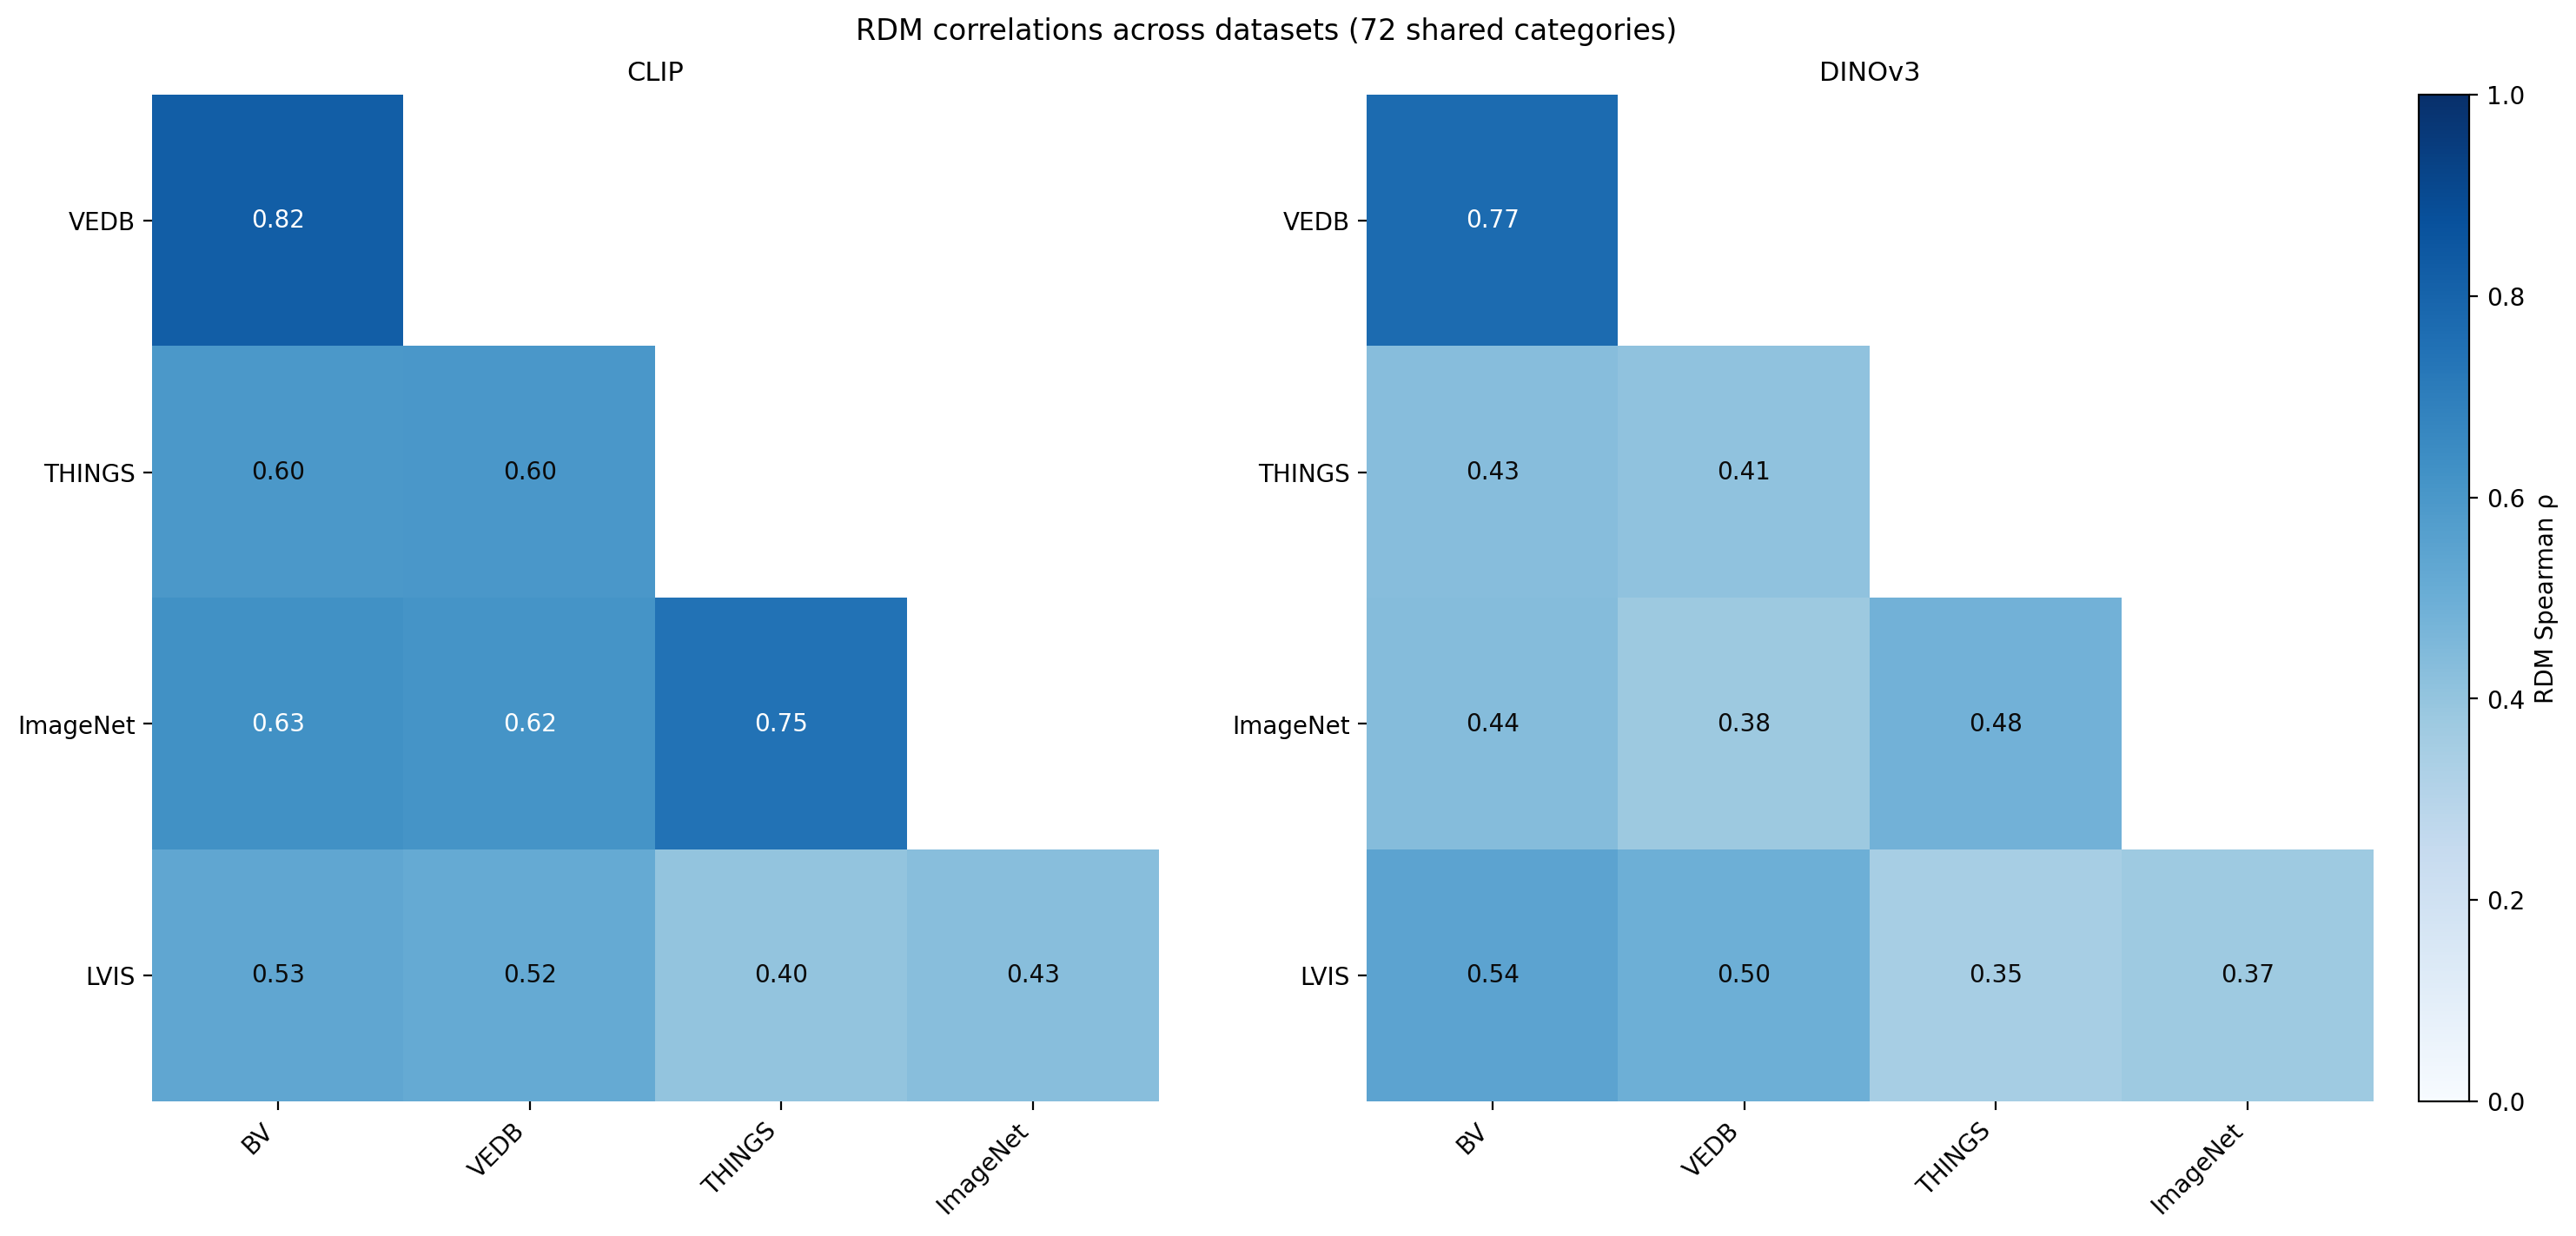

`outputs/rdm_matrices/bv_vedb_things_imagenet_lvis/figures/rdm_correlation_matrix_backbones_bv_vedb_things_imagenet_lvis.png`

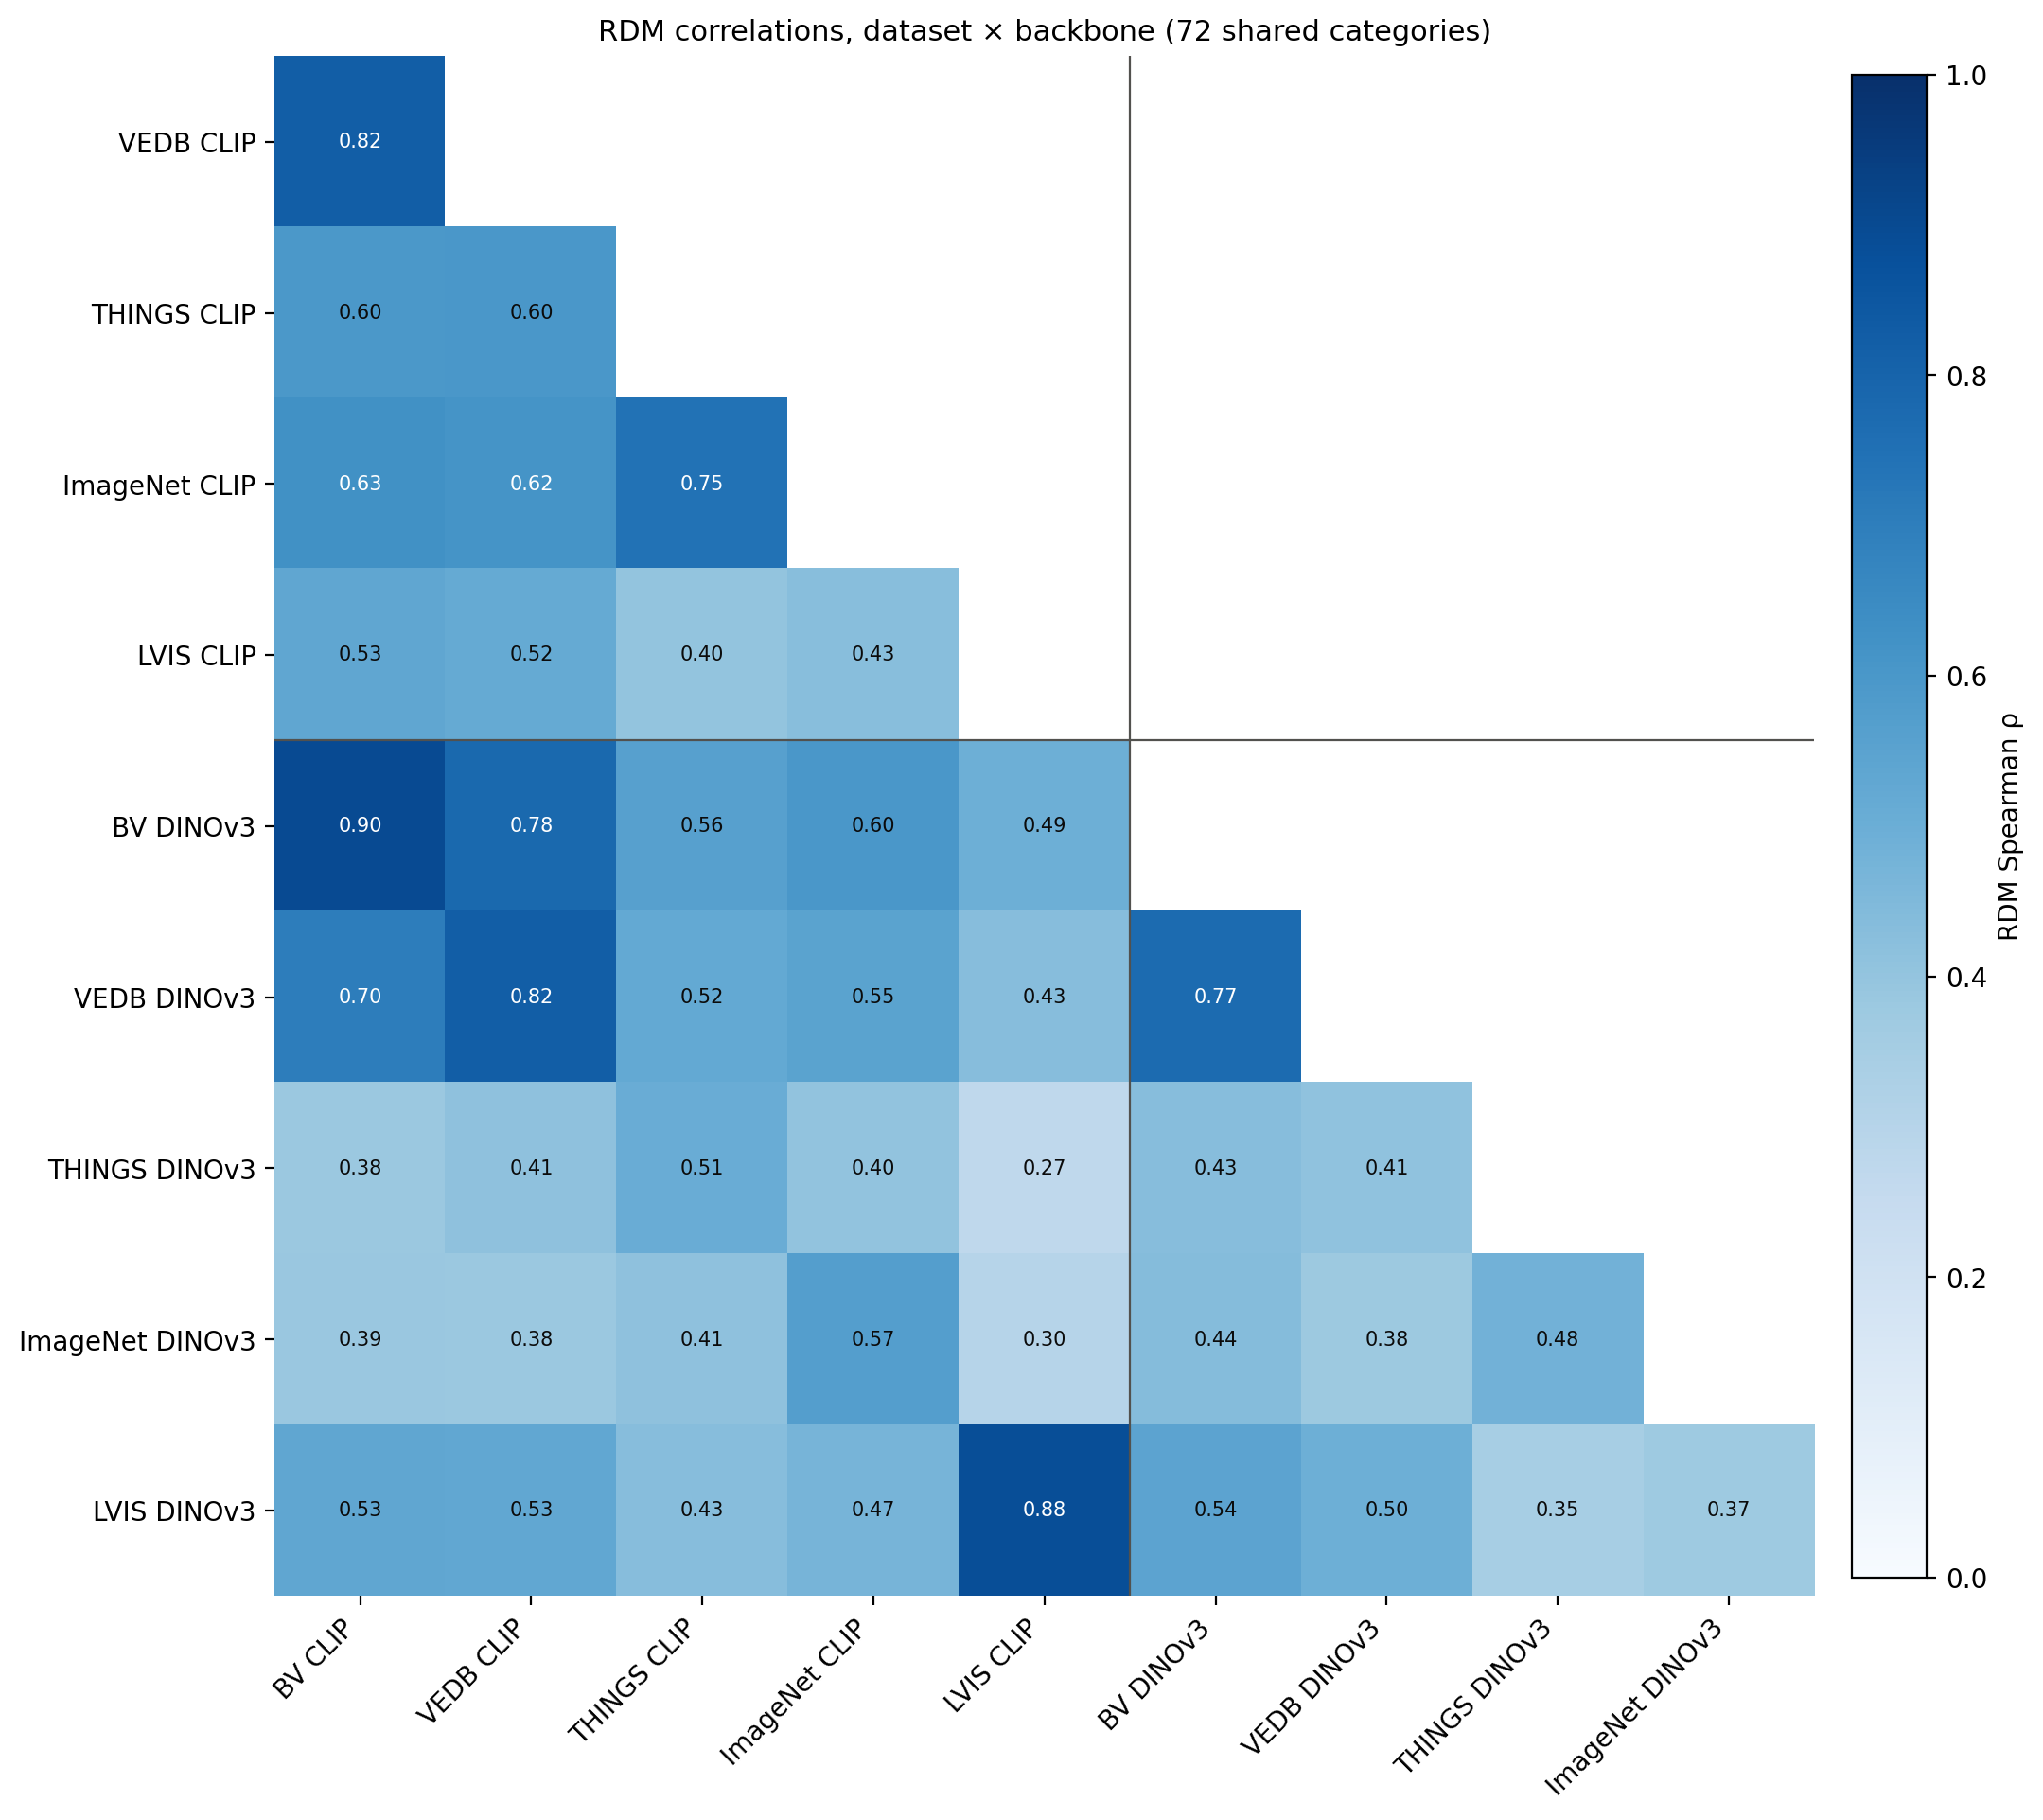

In [8]:
t = "_".join(DATASETS)
f = OUT / "rdm_matrices" / t / "figures"
show_images([f / f"rdm_correlation_matrix_{t}.png", f / f"rdm_correlation_matrix_backbones_{t}.png"], width=800)

### Review checklist

- Is every dataset z-scored on the same shared categories?
- Do the bootstrap CIs drop pairs of the same original category?